In [13]:
# CELL 1 — CONFIGURATION AND DATA FILE DISCOVERY
import sys, subprocess, importlib.util
for module, package in [('duckdb','duckdb>=1.1,<2'),('pandas','pandas>=2,<4'),('matplotlib','matplotlib>=3.7,<4')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable,'-m','pip','install','-q',package])
import duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

ROOT = Path('/content') if Path('/content').exists() else Path.cwd()
OUT = ROOT / 'NYC_Project8_Outputs'
OUT.mkdir(parents=True,exist_ok=True)
# Set this explicitly if more than one dataset is present.
DATA_FILE = None  # example: '/content/DOHMH_New_York_City_Restaurant_Inspection_Results.csv'
if DATA_FILE is None:
    candidates = [p for p in ROOT.glob('*.csv') if p.is_file() and not p.name.startswith('nyc_')]
    if not candidates:
        raise FileNotFoundError('Upload the restaurant-inspection CSV to Colab Files, or set DATA_FILE to your Drive path.')
    preferred = [p for p in candidates if any(x in p.name.lower() for x in ['restaurant','inspection','dohmh'])]
    if len(preferred)==1:
        DATA_FILE=preferred[0]
    elif len(candidates)==1:
        DATA_FILE=candidates[0]
    else:
        print('Candidate CSVs:',*[str(p) for p in candidates],sep='\n  ')
        raise ValueError('More than one candidate CSV: set DATA_FILE to the restaurant dataset path.')
DATA_FILE=Path(DATA_FILE)
assert DATA_FILE.exists(), f'Dataset not found: {DATA_FILE}'
print('Selected dataset:',DATA_FILE.name,'Size (MB):',round(DATA_FILE.stat().st_size/1e6,1))
print('If a data dictionary was supplied, retain it: use its field definitions to verify the interpretations below.')
DB_FILE=OUT/'nyc_restaurant_inspections.duckdb'
con=duckdb.connect(str(DB_FILE))
con.execute("SET memory_limit='3GB'")
con.execute('SET threads=2')

Selected dataset: DOHMH_New_York_City_Restaurant_Inspection_Results_20250919.csv Size (MB): 129.2
If a data dictionary was supplied, retain it: use its field definitions to verify the interpretations below.


In [14]:
# CELL 2 — ROBUST SQL CSV INGESTION AND COLUMN DISCOVERY
# The open-data feed has multiple violation rows per inspection; do not treat rows as independent inspections.
src=str(DATA_FILE).replace("'","''")
con.execute(f"""CREATE OR REPLACE TABLE raw_inspections AS SELECT *
    FROM read_csv('{src}', header=true, all_varchar=true,
        null_padding=true, strict_mode=false, ignore_errors=true)""")
columns=con.execute('DESCRIBE raw_inspections').df()['column_name'].tolist()
print('Parsed rows:',con.execute('SELECT COUNT(*) FROM raw_inspections').fetchone()[0]);print('Columns:',columns)

def normalize(name):
    return ''.join(c if c.isalnum() else '_' for c in str(name).strip().lower()).strip('_')
lookup={normalize(x):x for x in columns}
def col(*names):
    for name in names:
        key=normalize(name)
        if key in lookup:return '"'+lookup[key].replace('"','""')+'"'
    return 'NULL'
def string(x):return f"NULLIF(TRIM({x}), '')" if x!='NULL' else 'NULL::VARCHAR'
def number(x):return f"TRY_CAST({string(x)} AS DOUBLE)" if x!='NULL' else 'NULL::DOUBLE'
field={
 'camis':col('CAMIS','RESTAURANT ID'), 'dba':col('DBA','RESTAURANT NAME'),
 'borough':col('BORO','BOROUGH'), 'zip':col('ZIPCODE','ZIP CODE','ZIP'),
 'building':col('BUILDING'), 'street':col('STREET'),
 'cuisine':col('CUISINE DESCRIPTION','CUISINE'),
 'inspection_date':col('INSPECTION DATE'), 'grade_date':col('GRADE DATE'),
 'grade':col('GRADE'), 'score':col('SCORE'),
 'inspection_type':col('INSPECTION TYPE'), 'action':col('ACTION'),
 'violation_code':col('VIOLATION CODE'), 'violation_description':col('VIOLATION DESCRIPTION'),
 'critical_flag':col('CRITICAL FLAG'), 'record_date':col('RECORD DATE')}
missing=[k for k in ('camis','inspection_date','inspection_type','violation_description') if field[k]=='NULL']
assert not missing, 'Required fields not found: '+str(missing)+'; examine the data dictionary and column listing.'
display(pd.DataFrame({'logical_field':list(field),'source_column':[v if v!='NULL' else 'NOT PROVIDED' for v in field.values()]}))
print('CSV parser uses null_padding / non-strict mode and may skip irreparably malformed lines.')

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Parsed rows: 288888
Columns: ['CAMIS', 'DBA', 'BORO', 'BUILDING', 'STREET', 'ZIPCODE', 'PHONE', 'CUISINE DESCRIPTION', 'INSPECTION DATE', 'ACTION', 'VIOLATION CODE', 'VIOLATION DESCRIPTION', 'CRITICAL FLAG', 'SCORE', 'GRADE', 'GRADE DATE', 'RECORD DATE', 'INSPECTION TYPE', 'Latitude', 'Longitude', 'Community Board', 'Council District', 'Census Tract', 'BIN', 'BBL', 'NTA', 'Location Point1']


,logical_field,source_column
0,camis,"""CAMIS"""
1,dba,"""DBA"""
2,borough,"""BORO"""
3,zip,"""ZIPCODE"""
4,building,"""BUILDING"""
5,street,"""STREET"""
6,cuisine,"""CUISINE DESCRIPTION"""
7,inspection_date,"""INSPECTION DATE"""
8,grade_date,"""GRADE DATE"""
9,grade,"""GRADE"""


CSV parser uses null_padding / non-strict mode and may skip irreparably malformed lines.


In [15]:
# CELL 3 — STANDARDIZE AND AUDIT RECORDS (SQL)
def parsed_date(x):
    if x=='NULL':return 'NULL::DATE'
    return ('COALESCE('+','.join(f"TRY_STRPTIME({x}, '{fmt}')" for fmt in
             ['%m/%d/%Y','%Y-%m-%d','%m/%d/%y','%Y/%m/%d'])+')::DATE')
cuisine_expr=f"UPPER({string(field['cuisine'])})"
cuisine_norm=(f"CASE WHEN {cuisine_expr} IN ('ASIAN/CHINESE','CHINESE/ASIAN','CHINESE') THEN 'CHINESE' "
    f"WHEN {cuisine_expr} IN ('AMERICAN','AMERICAN (NEW)','AMERICAN (TRADITIONAL)') THEN 'AMERICAN' "
    f"WHEN {cuisine_expr} IN ('ITALIAN','ITALIAN/AMERICAN') THEN 'ITALIAN' "
    f"ELSE COALESCE({cuisine_expr},'UNKNOWN') END")
selected=[
 f"{string(field['camis'])} AS camis",f"{string(field['dba'])} AS restaurant_name",
 f"UPPER(COALESCE({string(field['borough'])},'UNKNOWN')) AS borough_raw",
 f"{string(field['zip'])} AS zip_code",f"UPPER({string(field['building'])}) AS building",
 f"UPPER({string(field['street'])}) AS street",f"{cuisine_norm} AS cuisine",
 f"{parsed_date(field['inspection_date'])} AS inspection_date",
 f"{parsed_date(field['grade_date'])} AS grade_date",
 f"UPPER({string(field['grade'])}) AS grade",f"{number(field['score'])} AS score",
 f"UPPER({string(field['inspection_type'])}) AS inspection_type",
 f"UPPER({string(field['action'])}) AS action",
 f"UPPER({string(field['violation_code'])}) AS violation_code",
 f"{string(field['violation_description'])} AS violation_description",
 f"UPPER({string(field['critical_flag'])}) AS critical_flag",
 f"{parsed_date(field['record_date'])} AS record_date"]
con.execute('CREATE OR REPLACE TABLE inspection_rows AS SELECT '+', '.join(selected)+' FROM raw_inspections')
con.execute("""CREATE OR REPLACE VIEW rows_clean AS SELECT *,
    CASE WHEN borough_raw IN ('MANHATTAN','BRONX','BROOKLYN','QUEENS','STATEN ISLAND')
      THEN borough_raw WHEN borough_raw='0' THEN 'UNKNOWN' ELSE 'UNKNOWN' END AS borough,
    CASE WHEN critical_flag='CRITICAL' THEN 1 ELSE 0 END AS is_critical,
    CASE WHEN critical_flag='NOT CRITICAL' THEN 1 ELSE 0 END AS is_noncritical
    FROM inspection_rows""")
# Inspect the policy-relevant presence of multiple violation lines and uninspected future/open-case records.
quality=con.execute("""SELECT COUNT(*) source_rows,
 COUNT(*) FILTER(WHERE camis IS NULL) missing_camis,
 COUNT(*) FILTER(WHERE inspection_date IS NULL) missing_inspection_dates,
 COUNT(*) FILTER(WHERE borough='UNKNOWN') unknown_borough_rows,
 COUNT(*) FILTER(WHERE zip_code IS NULL) missing_zip_rows,
 COUNT(*) FILTER(WHERE street IS NULL) missing_street_rows,
 COUNT(*) FILTER(WHERE cuisine='UNKNOWN') unknown_cuisine_rows,
 COUNT(*) FILTER(WHERE grade IS NULL) missing_grade_rows,
 COUNT(*) FILTER(WHERE score IS NULL) missing_score_rows,
 COUNT(*) FILTER(WHERE violation_description IS NULL) no_violation_description_rows,
 COUNT(*) FILTER(WHERE critical_flag IS NULL) missing_critical_flag_rows,
 MIN(inspection_date) earliest_inspection, MAX(inspection_date) latest_inspection
 FROM rows_clean""").df()
quality.to_csv(OUT/'nyc_inspection_data_quality.csv',index=False)
display(quality.T.rename(columns={0:'value'}))
print('Note: missing grade is common for inspections not assigned a grade. Unknown critical labels are not assumed non-critical.')

,value
source_rows,288888
missing_camis,0
missing_inspection_dates,0
unknown_borough_rows,15
missing_zip_rows,2908
missing_street_rows,0
unknown_cuisine_rows,3699
missing_grade_rows,148044
missing_score_rows,15926
no_violation_description_rows,5851


Note: missing grade is common for inspections not assigned a grade. Unknown critical labels are not assumed non-critical.


In [16]:

# CELL 4 — VALID INSPECTION EVENTS AND PLACEHOLDER DATE AUDIT

# Keep the original raw records, but exclude unverified
# 1900-01-01 placeholder dates from analytical summaries.

placeholder_audit = con.execute("""
SELECT
    COUNT(*) AS excluded_source_rows,
    COUNT(DISTINCT (
        camis,
        inspection_date,
        COALESCE(inspection_type, 'UNKNOWN')
    )) AS excluded_proxy_events
FROM rows_clean
WHERE inspection_date = DATE '1900-01-01'
""").df()

placeholder_audit["placeholder_date"] = "1900-01-01"
placeholder_audit["reason"] = (
    "Suspected administrative/default date; "
    "excluded pending data dictionary confirmation"
)

placeholder_audit.to_csv(
    OUT / "nyc_inspection_placeholder_date_audit.csv",
    index=False
)

display(placeholder_audit)

# Rebuild the inspection-level analytical table.
con.execute("""
CREATE OR REPLACE TABLE inspection_events AS
SELECT
    camis,
    inspection_date,
    COALESCE(inspection_type, 'UNKNOWN') AS inspection_type,
    ANY_VALUE(restaurant_name) AS restaurant_name,
    ANY_VALUE(borough) AS borough,
    ANY_VALUE(zip_code) AS zip_code,
    ANY_VALUE(street) AS street,
    ANY_VALUE(cuisine) AS cuisine,

    MAX(score) FILTER (WHERE score >= 0) AS score,

    CASE
        WHEN COUNT(DISTINCT grade)
            FILTER (WHERE grade IN ('A', 'B', 'C')) = 1
        THEN MAX(grade)
            FILTER (WHERE grade IN ('A', 'B', 'C'))
        ELSE NULL
    END AS grade,

    COUNT(*) AS source_rows,

    COUNT(*) FILTER (
        WHERE violation_description IS NOT NULL
    ) AS violation_rows,

    COUNT(*) FILTER (
        WHERE is_critical = 1
          AND violation_description IS NOT NULL
    ) AS critical_rows,

    COUNT(DISTINCT grade)
        FILTER (WHERE grade IN ('A', 'B', 'C'))
        AS distinct_abc_grades,

    COUNT(DISTINCT score)
        FILTER (WHERE score IS NOT NULL)
        AS distinct_scores,

    COUNT(DISTINCT borough) AS distinct_boroughs,
    COUNT(DISTINCT cuisine) AS distinct_cuisines

FROM rows_clean

WHERE camis IS NOT NULL
  AND inspection_date IS NOT NULL
  AND inspection_date <> DATE '1900-01-01'

GROUP BY
    camis,
    inspection_date,
    COALESCE(inspection_type, 'UNKNOWN')
""")

# Recheck event identity and row reconciliation.
checks = con.execute("""
SELECT
    COUNT(*) AS inspection_events,
    SUM(source_rows) AS source_rows_in_events,

    SUM(CASE WHEN distinct_abc_grades > 1
        THEN 1 ELSE 0 END) AS conflicting_grades,

    SUM(CASE WHEN distinct_scores > 1
        THEN 1 ELSE 0 END) AS conflicting_scores,

    SUM(CASE WHEN distinct_boroughs > 1
        THEN 1 ELSE 0 END) AS conflicting_boroughs,

    SUM(CASE WHEN distinct_cuisines > 1
        THEN 1 ELSE 0 END) AS conflicting_cuisines,

    SUM(CASE WHEN source_rows > 1
        THEN 1 ELSE 0 END) AS multi_row_inspections

FROM inspection_events
""").df()

checks.to_csv(
    OUT / "nyc_inspection_event_audit.csv",
    index=False
)

valid_source = con.execute("""
SELECT COUNT(*)
FROM rows_clean
WHERE camis IS NOT NULL
  AND inspection_date IS NOT NULL
  AND inspection_date <> DATE '1900-01-01'
""").fetchone()[0]

assert int(checks.inspection_events.iloc[0]) > 0
assert int(checks.source_rows_in_events.iloc[0]) == valid_source

remaining_1900 = con.execute("""
SELECT COUNT(*)
FROM inspection_events
WHERE inspection_date = DATE '1900-01-01'
""").fetchone()[0]

assert remaining_1900 == 0, (
    "Placeholder dates remain in analytical events."
)

print("=" * 55)
print("CELL 4 STATUS: PASS")
print("=" * 55)
print(
    "Excluded placeholder events:",
    int(placeholder_audit.excluded_proxy_events.iloc[0])
)
print(
    "Valid analytical inspection events:",
    int(checks.inspection_events.iloc[0])
)
print("1900 dates in inspection_events: 0")
print("Event reconciliation: PASS")
print("Raw records preserved for auditing.")
print("Ready for Cells 5, 6 and 7.")


,excluded_source_rows,excluded_proxy_events,placeholder_date,reason
0,3699,3699,1900-01-01,Suspected administrative/default date; exclude...


CELL 4 STATUS: PASS
Excluded placeholder events: 3699
Valid analytical inspection events: 91316
1900 dates in inspection_events: 0
Event reconciliation: PASS
Raw records preserved for auditing.
Ready for Cells 5, 6 and 7.


In [17]:

# ============================================================
# CELL 5 — SQL INSPECTION, VIOLATION, CUISINE & NEIGHBORHOOD METRICS
# PROJECT 8 — CORRECTED VERSION
# ============================================================

def export(name, query):
    table = con.execute(query).df()
    table.to_csv(OUT / f"nyc_{name}.csv", index=False)
    return table


# 1. ANNUAL INSPECTION TRENDS
annual = export("inspection_annual_trends", """
SELECT
    YEAR(inspection_date) AS "year",
    COUNT(*) AS inspection_events,
    COUNT(*) FILTER (
        WHERE grade IN ('A', 'B', 'C')
    ) AS graded_events,
    ROUND(
        AVG(score) FILTER (WHERE score >= 0), 2
    ) AS avg_violation_score,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE grade = 'A')
        / NULLIF(
            COUNT(*) FILTER (WHERE grade IN ('A', 'B', 'C')),
            0
        ), 2
    ) AS pct_a_among_abc
FROM inspection_events
GROUP BY 1
ORDER BY 1
""")


# 2. BOROUGH INSPECTION SUMMARY
borough = export("inspection_borough_summary", """
SELECT
    borough,
    COUNT(*) AS inspection_events,
    COUNT(*) FILTER (
        WHERE grade IN ('A', 'B', 'C')
    ) AS graded_events,
    COUNT(*) FILTER (
        WHERE grade = 'A'
    ) AS grade_a,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE grade = 'A')
        / NULLIF(
            COUNT(*) FILTER (WHERE grade IN ('A', 'B', 'C')),
            0
        ), 2
    ) AS pct_a_among_abc,
    ROUND(
        AVG(score) FILTER (WHERE score >= 0), 2
    ) AS avg_violation_score,
    SUM(critical_rows) AS critical_violation_rows,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE critical_rows > 0)
        / NULLIF(COUNT(*), 0), 2
    ) AS pct_events_with_critical
FROM inspection_events
GROUP BY borough
ORDER BY inspection_events DESC
""")


# 3. GRADE DISTRIBUTION
grades = export("inspection_grade_distribution", """
SELECT
    COALESCE(grade, 'UNASSIGNED/OTHER') AS grade_group,
    COUNT(*) AS inspection_events
FROM inspection_events
GROUP BY 1
ORDER BY inspection_events DESC
""")


# 4. INSPECTION TYPES
types = export("inspection_type_summary", """
SELECT
    inspection_type,
    COUNT(*) AS inspection_events
FROM inspection_events
GROUP BY 1
ORDER BY inspection_events DESC
""")


# 5. TOP VIOLATIONS
violations = export("inspection_top_violations", """
SELECT
    COALESCE(violation_code, 'NO CODE') AS violation_code,
    COALESCE(
        violation_description, 'NO DESCRIPTION'
    ) AS violation_description,
    COUNT(*) AS mentions,
    COUNT(*) FILTER (
        WHERE is_critical = 1
    ) AS critical_mentions,
    COUNT(DISTINCT (
        camis, inspection_date, inspection_type
    )) AS affected_inspection_proxy_keys
FROM rows_clean
WHERE violation_description IS NOT NULL
  AND camis IS NOT NULL
  AND inspection_date IS NOT NULL
GROUP BY 1, 2
ORDER BY mentions DESC
LIMIT 25
""")


# 6. CRITICAL VS NON-CRITICAL VIOLATIONS
critical = export("inspection_critical_status", """
SELECT
    CASE
        WHEN critical_flag = 'CRITICAL'
            THEN 'CRITICAL'
        WHEN critical_flag = 'NOT CRITICAL'
            THEN 'NOT CRITICAL'
        ELSE 'OTHER/UNKNOWN'
    END AS critical_status,
    COUNT(*) AS violation_rows
FROM rows_clean
WHERE violation_description IS NOT NULL
GROUP BY 1
ORDER BY violation_rows DESC
""")


# 7. CRITICAL VIOLATIONS BY BOROUGH
borough_factors = export("inspection_critical_by_borough", """
SELECT
    borough,
    COUNT(*) AS inspection_events,
    COUNT(*) FILTER (
        WHERE critical_rows > 0
    ) AS events_with_critical,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE critical_rows > 0)
        / NULLIF(COUNT(*), 0), 2
    ) AS pct_events_with_critical,
    SUM(critical_rows) AS critical_violation_rows
FROM inspection_events
GROUP BY 1
ORDER BY pct_events_with_critical DESC
""")


# 8. CUISINE ANALYSIS
cuisine = export("inspection_cuisine_summary", """
SELECT
    cuisine,
    COUNT(*) AS inspection_events,
    COUNT(*) FILTER (
        WHERE grade IN ('A', 'B', 'C')
    ) AS graded_events,
    ROUND(
        AVG(score) FILTER (WHERE score >= 0), 2
    ) AS avg_violation_score,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE grade = 'A')
        / NULLIF(
            COUNT(*) FILTER (WHERE grade IN ('A', 'B', 'C')),
            0
        ), 2
    ) AS pct_a_among_abc,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE critical_rows > 0)
        / NULLIF(COUNT(*), 0), 2
    ) AS pct_events_with_critical
FROM inspection_events
GROUP BY 1
ORDER BY inspection_events DESC
""")


# 9. CUISINES WITH HIGHEST AVERAGE VIOLATION SCORES
# Higher scores indicate worse inspection findings.
# Require at least 30 inspection events.

worst_cuisine = (
    cuisine[
        (cuisine["inspection_events"] >= 30)
        & (cuisine["cuisine"] != "UNKNOWN")
    ]
    .sort_values(
        "avg_violation_score",
        ascending=False
    )
    .head(5)
)

worst_cuisine.to_csv(
    OUT / "nyc_inspection_highest_violation_score_cuisines.csv",
    index=False
)


# 10. ZIP CODE ANALYSIS
# ZIP code is a geographic proxy, not an official neighborhood.

zipcodes = export("inspection_zip_summary", """
SELECT
    borough,
    COALESCE(zip_code, 'UNKNOWN') AS zip_code,
    COUNT(*) AS inspection_events,
    ROUND(
        AVG(score) FILTER (WHERE score >= 0), 2
    ) AS avg_violation_score,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE critical_rows > 0)
        / NULLIF(COUNT(*), 0), 2
    ) AS pct_events_with_critical
FROM inspection_events
GROUP BY 1, 2
ORDER BY inspection_events DESC
""")


# 11. MONTHLY INSPECTION TRENDS
monthly = export("inspection_monthly_trends", """
SELECT
    DATE_TRUNC('month', inspection_date)::DATE AS month,
    COUNT(*) AS inspection_events,
    ROUND(
        AVG(score) FILTER (WHERE score >= 0), 2
    ) AS avg_violation_score,
    SUM(critical_rows) AS critical_violation_rows
FROM inspection_events
GROUP BY 1
ORDER BY 1
""")


# ============================================================
# 12. DATA VALIDATION
# ============================================================

total_events = con.execute("""
SELECT COUNT(*)
FROM inspection_events
""").fetchone()[0]

assert int(borough["inspection_events"].sum()) == total_events, (
    "Borough event counts do not reconcile."
)

assert int(annual["inspection_events"].sum()) == total_events, (
    "Annual event counts do not reconcile."
)

assert int(grades["inspection_events"].sum()) == total_events, (
    "Grade event counts do not reconcile."
)

assert int(types["inspection_events"].sum()) == total_events, (
    "Inspection type counts do not reconcile."
)


# ============================================================
# 13. DISPLAY RESULTS
# ============================================================

print("=" * 60)
print("PROJECT 8 — CELL 5 COMPLETED")
print("=" * 60)

print(f"Total inspection events: {total_events:,}")
print("Annual trends: PASS")
print("Borough analysis: PASS")
print("Grade distribution: PASS")
print("Violation analysis: PASS")
print("Cuisine analysis: PASS")
print("ZIP analysis: PASS")
print("Monthly trends: PASS")

print("\nTOP 10 VIOLATIONS")
display(violations.head(10))

print("\nBOROUGH SUMMARY")
display(borough)

print("\nTOP 5 CUISINES BY AVERAGE VIOLATION SCORE")
display(worst_cuisine)

print("\nIMPORTANT:")
print("Higher inspection scores mean more violation points.")
print("Missing grades are excluded from the A/B/C denominator.")
print("ZIP codes are geographic proxies, not verified neighborhoods.")

print("\nCELL 5 STATUS: PASS")
print("Ready for Cell 6.")


PROJECT 8 — CELL 5 COMPLETED
Total inspection events: 91,316
Annual trends: PASS
Borough analysis: PASS
Grade distribution: PASS
Violation analysis: PASS
Cuisine analysis: PASS
ZIP analysis: PASS
Monthly trends: PASS

TOP 10 VIOLATIONS


,violation_code,violation_description,mentions,critical_mentions,affected_inspection_proxy_keys
0,10F,Non-food contact surface or equipment made of ...,35758,0,35758
1,08A,Establishment is not free of harborage or cond...,24103,0,24103
2,06D,"Food contact surface not properly washed, rins...",18596,18596,18595
3,02G,Cold TCS food item held above 41 °F; smoked or...,16240,16240,16240
4,10B,Anti-siphonage or back-flow prevention device ...,16045,0,16045
5,04L,Evidence of mice or live mice in establishment...,13647,13647,13647
6,02B,Hot TCS food item not held at or above 140 °F.,13557,13557,13557
7,06C,"Food, supplies, or equipment not protected fro...",12290,12290,12290
8,04N,Filth flies or food/refuse/sewage associated w...,7815,7815,7815
9,04A,Food Protection Certificate (FPC) not held by ...,7153,7153,7153



BOROUGH SUMMARY


,borough,inspection_events,graded_events,grade_a,pct_a_among_abc,avg_violation_score,critical_violation_rows,pct_events_with_critical
0,MANHATTAN,34676,19258,17130,88.95,16.84,55726.0,76.49
1,BROOKLYN,23811,13244,11580,87.44,17.57,40066.0,78.09
2,QUEENS,21296,11403,9737,85.39,18.67,37972.0,78.86
3,BRONX,8265,4540,3860,85.02,17.27,13886.0,79.25
4,STATEN ISLAND,3268,1871,1654,88.40,16.64,5489.0,83.20



TOP 5 CUISINES BY AVERAGE VIOLATION SCORE


,cuisine,inspection_events,graded_events,avg_violation_score,pct_a_among_abc,pct_events_with_critical
37,BANGLADESHI,356,113,29.84,58.41,76.69
58,CREOLE,106,43,25.81,53.49,83.96
34,AFRICAN,373,142,24.94,67.61,75.60
51,PAKISTANI,141,58,24.82,62.07,78.01
48,FILIPINO,157,59,24.76,55.93,73.89



IMPORTANT:
Higher inspection scores mean more violation points.
Missing grades are excluded from the A/B/C denominator.
ZIP codes are geographic proxies, not verified neighborhoods.

CELL 5 STATUS: PASS
Ready for Cell 6.


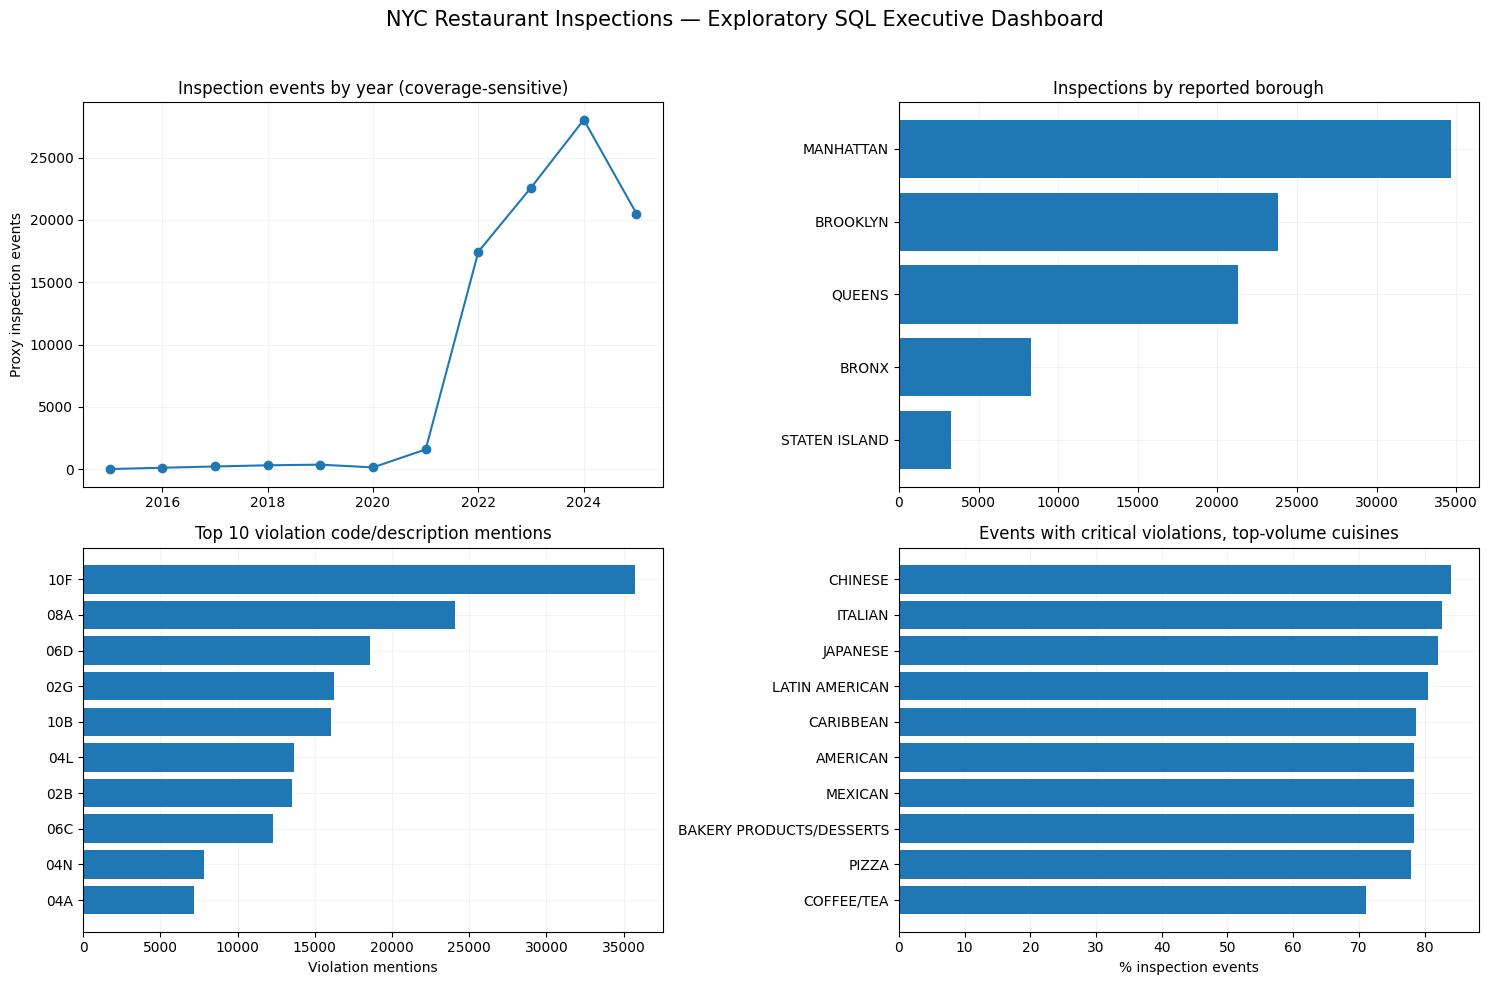

VISUALIZATION AND RECONCILIATION: PASS
Inspection period: 1900-01-01 00:00:00 to 2025-09-16 00:00:00


In [18]:
# CELL 6 — EXECUTIVE VISUALS AND DETERMINISTIC VALIDATION
fig,axs=plt.subplots(2,2,figsize=(15,10))
axs[0,0].plot(annual.year,annual.inspection_events,marker='o');axs[0,0].set_title('Inspection events by year (coverage-sensitive)');axs[0,0].set_ylabel('Proxy inspection events')
plotb=borough.loc[borough.borough!='UNKNOWN'].sort_values('inspection_events')
axs[0,1].barh(plotb.borough,plotb.inspection_events);axs[0,1].set_title('Inspections by reported borough')
topv=violations.head(10).iloc[::-1]
axs[1,0].barh(topv.violation_code,topv.mentions);axs[1,0].set_title('Top 10 violation code/description mentions');axs[1,0].set_xlabel('Violation mentions')
plotc=cuisine.query('inspection_events>=30 and cuisine!="UNKNOWN"').sort_values('inspection_events',ascending=False).head(10).sort_values('pct_events_with_critical')
axs[1,1].barh(plotc.cuisine,plotc.pct_events_with_critical);axs[1,1].set_title('Events with critical violations, top-volume cuisines');axs[1,1].set_xlabel('% inspection events')
for a in axs.flat:a.grid(alpha=.15);a.set_axisbelow(True)
fig.suptitle('NYC Restaurant Inspections — Exploratory SQL Executive Dashboard',fontsize=15)
fig.tight_layout(rect=[0,0,1,.96]);fig.savefig(OUT/'nyc_restaurant_inspection_dashboard.png',dpi=160,bbox_inches='tight');plt.show()
assert int(annual.inspection_events.sum())>0
assert int(grades.inspection_events.sum())==int(annual.inspection_events.sum())
assert int(types.inspection_events.sum())==int(annual.inspection_events.sum())
print('VISUALIZATION AND RECONCILIATION: PASS')
print('Inspection period:',quality.earliest_inspection.iloc[0],'to',quality.latest_inspection.iloc[0])

In [19]:
# CELL 7 — EVIDENCE-BASED README, RECOMMENDATIONS & PACKAGING
from zipfile import ZipFile, ZIP_DEFLATED

def mdtable(frame, cols, limit=10):
    if frame is None or frame.empty:return 'No observations available.'
    t=frame.loc[:,cols].head(limit).copy()
    for c in t.columns:
        if isinstance(t[c].dtype,pd.CategoricalDtype):t[c]=t[c].astype(str)
        elif pd.api.types.is_numeric_dtype(t[c]):t[c]=t[c].round(2)
    rows=[['—' if pd.isna(v) else str(v).replace('|','/') for v in row] for row in t.itertuples(index=False,name=None)]
    return '| '+' | '.join(cols)+' |\n| '+' | '.join(['---']*len(cols))+' |\n'+'\n'.join('| '+' | '.join(row)+' |' for row in rows)

first=str(quality.earliest_inspection.iloc[0]);last=str(quality.latest_inspection.iloc[0]);n=int(annual.inspection_events.sum())
top_factor=violations.violation_description.iloc[0] if not violations.empty else 'Not available'
worst=worst_cuisine.cuisine.iloc[0] if len(worst_cuisine) else 'Not available at minimum sample threshold'
readme=f'''# NYC Restaurant Food Safety — SQL Inspection Intelligence

![Restaurant Inspection Dashboard](nyc_restaurant_inspection_dashboard.png)

## Business objective
Evaluate NYC restaurant inspection violations, grades, cuisines, boroughs, and geographic/time patterns to support equitable and effective food-safety policy.

## Dataset and definitions
- Raw file: `{DATA_FILE.name}`; raw records parsed: **{int(quality.source_rows.iloc[0]):,}**.
- Proxy inspection events: **{n:,}**; inspection dates **{first}** through **{last}**.
- A source row generally represents an inspection-violation record, **not necessarily one inspection**.
- An inspection event is approximated by `CAMIS + inspection date + inspection type`; repeated same-day inspections of one type may be merged. No verified encounter identifier exists.
- Scores represent **violation points** (higher is worse), not satisfaction or performance points. Grade analysis includes A/B/C where present; unassigned/other grade events are counted separately.
- Critical status is reported status, not a causal measure. Missing values are unknown, not automatically non-critical.
- ZIP code is a geographic proxy, **not a verified neighborhood**.
- Outputs cover the actual source extract, **not necessarily all current NYC restaurants**. Avoid comparing annual totals without ensuring complete matching periods.

## Executive quality audit
{mdtable(quality,list(quality.columns),1)}

## Event-key audit
{mdtable(checks,list(checks.columns),1)}

## Annual inspection trend
{mdtable(annual,['year','inspection_events','graded_events','avg_violation_score','pct_a_among_abc'],20)}

## Inspections and grades by borough
{mdtable(borough,['borough','inspection_events','graded_events','pct_a_among_abc','avg_violation_score','pct_events_with_critical'],10)}

## NYC grade distribution
{mdtable(grades,['grade_group','inspection_events'],12)}

## Most frequent inspection types
{mdtable(types,['inspection_type','inspection_events'],10)}

## Top 10 violation mentions
{mdtable(violations,['violation_code','violation_description','mentions','critical_mentions'],10)}

A single event may contain multiple different violation mentions. Mentions are not unique restaurants or inspections.

## Critical vs non-critical violation rows
{mdtable(critical,['critical_status','violation_rows'],6)}

## Highest-scoring cuisines (worse reported violation points)
Uses at least 30 proxy inspection events per cuisine; exploratory only, not an exposure-adjusted restaurant risk estimate.
{mdtable(worst_cuisine,['cuisine','inspection_events','avg_violation_score','pct_a_among_abc','pct_events_with_critical'],5)}

## ZIP / geographic analysis
`nyc_inspection_zip_summary.csv` includes ZIP-level proxy event counts and rates. Borough counts are not per-restaurant risk rates; repeated inspections are common, and restaurant mix varies.

## Methodology and validation
1. Scan large CSV using DuckDB SQL with nullable, tolerant parsing; irrecoverably malformed rows may be skipped and must be separately reconciled for official reporting.
2. Inspect fields against the supplied data dictionary and audit missing dates, boroughs, ZIP codes, cuisines, and grades.
3. Standardize commonly equivalent cuisine labels conservatively and convert inspection/grade dates.
4. Construct proxy inspection-level events to avoid counting violation rows as separate inspections.
5. Audit conflicting grades, scores, boroughs and cuisines within inspection events. Conflicting A/B/C grades are unassigned rather than arbitrarily selected.
6. Generate SQL summaries; reconcile event totals between annual, borough and grade exports.
7. Save charts, CSV outputs, recommendations and a ZIP package.

## Business recommendations
See [RECOMMENDATIONS.md](RECOMMENDATIONS.md) for seven prioritized, measurable recommendations. Largest raw volume is not the same as greatest safety risk.

## Technology
Python, DuckDB SQL, pandas, NumPy, Matplotlib and Google Colab. This release includes a static Python dashboard and Power BI-ready CSVs; **no finished Power BI report**.

## Reproduction
1. Obtain the NYC DOHMH restaurant inspection CSV from the original assignment or authorized NYC open-data source, verify the data dictionary and licensing.
2. Upload `NYC_Restaurant_Inspection_SQL_Analysis.ipynb` to Google Colab.
3. Upload the source CSV to `/content` or Google Drive; set `DATA_FILE` in Cell 1 if needed.
4. Run cells 1–7 and check printed `VALIDATION: PASS` and `PACKAGE READY` messages.
5. Read exports from `/content/NYC_Project8_Outputs`. Download the notebook `.ipynb` separately and add it to the extracted ZIP files before GitHub publishing.

## Limitations
Data feed may contain updated, administrative, and ungraded records; the proxy event key may merge inspections. Missing grades are not failures. Cuisine normalization is limited; score differences may reflect inspection type and selection effects. Annual trends may have incomplete boundary-year coverage. ZIP codes are not neighborhoods. Rates by borough or cuisine are conditioned on recorded inspections, not all restaurants. No official individual-restaurant or neighborhood risk ranking is claimed. The original raw CSV is excluded from the ZIP by default because of its possible large size.

## GitHub publishing
**Repository:** `NYC-Restaurant-Food-Safety-Inspection-Analytics`
**Description:** SQL-based NYC restaurant inspection analytics exploring food safety violations, grades, cuisine patterns, geographic differences, and targeted policy actions.
**Create repository:** https://github.com/new
'''
(OUT/'README.md').write_text(readme,encoding='utf-8')
recs=f'''# NYC Restaurant Inspection — Policy Recommendations

## Decision standard
Findings are descriptive associations in recorded inspections, not proof of restaurant, neighborhood or cuisine-specific inherent risk. Validate individual enforcement decisions using current records, case history, and consistent policies.

## 1. Prioritize repeat critical violations (Critical)
**Evidence:** Critical-violation-bearing inspection events are measured by borough and cuisine.\n**Action:** Identify repeat patterns at the restaurant level after reconciling events; schedule fair, risk-based follow-ups.\n**Measure:** Verified repeat critical violations per inspected restaurant and follow-up compliance.

## 2. Target the most frequent specific violations (High)
**Evidence:** Most frequently mentioned description: **{top_factor}**.\n**Action:** Provide issue-specific operator training and publish clear inspection checklists.\n**Measure:** Subsequent violation mentions per reinspection, controlling for inspection type.

## 3. Validate low-performance cuisine segments before intervention (High)
**Evidence:** Highest average violation points among cuisines with >=30 proxy events: **{worst}**.\n**Action:** Examine sample size, inspection mix and repeated establishments before tailoring language-accessible education.\n**Measure:** Score improvement among comparable inspection types and cohorts; no stereotype-based enforcement.

## 4. Investigate geographic concentrations (High)
**Evidence:** Borough and ZIP code reports show counts and critical-event shares.\n**Action:** Validate hotspots using street address, inspection history and number of active inspected restaurants; prioritize on-site technical assistance.\n**Measure:** Critical events per completed inspection by comparable period and inspection type.

## 5. Improve grade transparency (High)
**Evidence:** Ungraded and other records are separated from A/B/C grade counts.\n**Action:** Track grade assignment status by inspection type and time; ensure clear public definitions.\n**Measure:** Share of eligible graded inspections with documented grades.

## 6. Harmonize restaurant coding and event identity (Critical)
**Evidence:** Raw rows can contain multiple violations from one event; IDs and inspection types are used as an event proxy.\n**Action:** Standardize cuisine taxonomy, inspection event identifiers and contradictory grade/score observations; reconcile with source dictionary.\n**Measure:** Zero unresolved duplicate-event or contradictory-grade exceptions.

## 7. Report time trends with comparable coverage (High)
**Evidence:** Extract dates range from **{first}** to **{last}**.\n**Action:** Compare complete year periods and consistent inspection categories; exclude incomplete years from trend claims.\n**Measure:** Year-over-year critical-event share with consistent definitions and confidence intervals where appropriate.

## Implementation roadmap
**0–30 days:** Confirm extract coverage and source dictionary; audit event-key collisions; validate top violations.
**30–90 days:** Run targeted training and geographic field reviews; evaluate inspector consistency.
**Quarterly:** Monitor reinspection compliance, critical violations and grade completeness.

## Interpretation caveats
Higher violation score is worse. Critical counts are inspection-based, not population risk. More inspections may reflect enforcement targeting. Do not infer causation or use raw cuisine differences to stigmatize communities.
'''
(OUT/'RECOMMENDATIONS.md').write_text(recs,encoding='utf-8')
(OUT/'requirements.txt').write_text('duckdb>=1.1,<2\npandas>=2,<4\nnumpy>=1.24,<3\nmatplotlib>=3.7,<4\n',encoding='utf-8')
(OUT/'.gitignore').write_text('*.duckdb\n*.wal\n__pycache__/\n.ipynb_checkpoints/\n.DS_Store\n',encoding='utf-8')
files=sorted(p for p in OUT.iterdir() if p.is_file() and p.suffix.lower() in ('.csv','.png','.md','.txt'))
files.append(OUT/'.gitignore')
required_names={'README.md','RECOMMENDATIONS.md','nyc_inspection_annual_trends.csv','nyc_inspection_borough_summary.csv','nyc_inspection_top_violations.csv','nyc_restaurant_inspection_dashboard.png'}
assert all((OUT/x).exists() for x in required_names)
zip_path=ROOT/'NYC_Project8_Restaurant_Inspection_Portfolio.zip'
with ZipFile(zip_path,'w',ZIP_DEFLATED) as z:
    for p in files:z.write(p,arcname=p.name)
with ZipFile(zip_path) as z:
    assert z.testzip() is None and required_names.issubset(set(z.namelist()))
print('VALIDATION: PASS — required report exports present')
print('README: CREATED; RECOMMENDATIONS: CREATED')
print('ZIP INTEGRITY: PASS; PACKAGED FILES:',len(files))
print('PACKAGE READY:',zip_path.name)
print('Notebook download: File → Download → Download .ipynb (separately)')
if ROOT==Path('/content'):
    from google.colab import files as colab_files
    colab_files.download(str(zip_path))

VALIDATION: PASS — required report exports present
README: CREATED; RECOMMENDATIONS: CREATED
ZIP INTEGRITY: PASS; PACKAGED FILES: 19
PACKAGE READY: NYC_Project8_Restaurant_Inspection_Portfolio.zip
Notebook download: File → Download → Download .ipynb (separately)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>